## Evaluation and validation of g-functions

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np

import pygfunction3 as gt3
import pygfunction as gt

### Field of 10 by 10 vertical boreholes

#### Borefield parameters

In [2]:
# Borehole dimensions and field layout
L = 150.        # Borehole length [m]
D = 4.          # Borehole buried depth [m]
r_b = 0.075     # Borehole radius [m]
N_1 = 10         # Number of boreholes in x-direction
N_2 = 10         # Number of boreholes in y-direction
B = 7.5         # Borehole spacing [m]

# Positions of the boreholes
p_head = np.array(
    [np.tile(B * np.arange(N_1), N_2), np.repeat(B * np.arange(N_2), N_1)]
).T

# Borefield object
field = gt3.Borefield(L=L, D=D, r_b=r_b, p_head=p_head)

#### Ground properties

In [3]:
k_s = 2.        # Soil conductivity [W/m/K]
alpha = 1e-6    # Soil diffusivity [m^2/s]

#### Parameters for the evaluation of g-functions

In [4]:
# Basis functions
n_nodes = 8
basis = gt3.Basis(n_nodes)

# Time array for g-function evaluation
t_s = L**2 / (9 * alpha)
tt_s = np.linspace(-10., 5., 25)
time = np.exp(tt_s) * t_s

#### Evaluation of the g-function

In [5]:
tic = perf_counter()
g_func, q_b, T_b = gt3.g_function(
    field,
    time=time,
    alpha=alpha,
    k_s=k_s,
    basis=basis,
    trf_backend='similarities',
    full_output=True,
    options={'rTol': 1e-2, 'sTol': 1e-2}
)
time_elapsed = perf_counter() - tic

Evaluating thermal response factors... done (0.14 seconds)
Solving for g-function... done (1.01 seconds)
Total time: 1.15 seconds


Time for the evaluation

In [6]:
%%timeit
g_func = gt3.g_function(
    field,
    time=time,
    alpha=alpha,
    k_s=k_s,
    basis=basis,
    trf_backend='similarities',
    options={'rTol': 1e-2, 'sTol': 1e-2},
    disp=False
)

1.15 s ± 32 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Reference using pygfunction v2

In [7]:
field_pygfunction = gt.borefield.Borefield.rectangle_field(
    N_1, N_2, B, B, L, D, r_b)
tic = perf_counter()
g_func_pygfunction = gt.gfunction.gFunction(
    field_pygfunction,
    alpha,
    time=time,
    method='similarities',
    options={'disp': True, 'nSegments': n_nodes}
).gFunc
time_elapsed_pygfunction = perf_counter() - tic

Identifying similarities ... 0.028 sec
------------------------------------------------------------
   Calculating g-function for boundary condition : 'UBWT'   
------------------------------------------------------------
Calculating segment to segment response factors ... 0.307 sec
Building and solving the system of equations ... 0.978 sec
Total time for g-function evaluation: 1.290 sec
------------------------------------------------------------


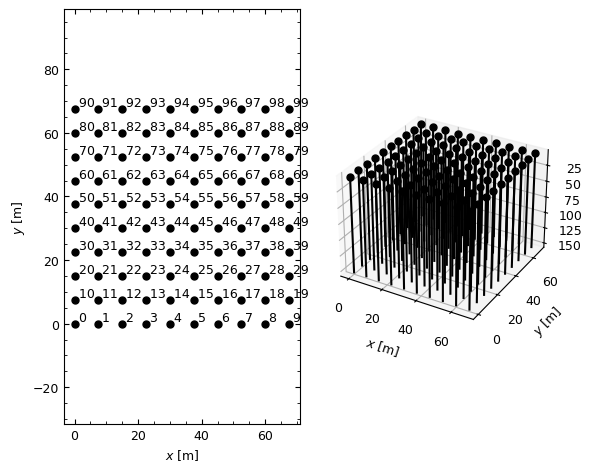

In [8]:
field_pygfunction.visualize_field();

Time for the evaluation using pygfunction v2

In [9]:
%%timeit
g_func_pygfunction = gt.gfunction.gFunction(
    field_pygfunction,
    alpha,
    time=time,
    method='similarities',
    options={'disp': False, 'nSegments': n_nodes}
).gFunc

1.3 s ± 24.1 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Compare g-functions

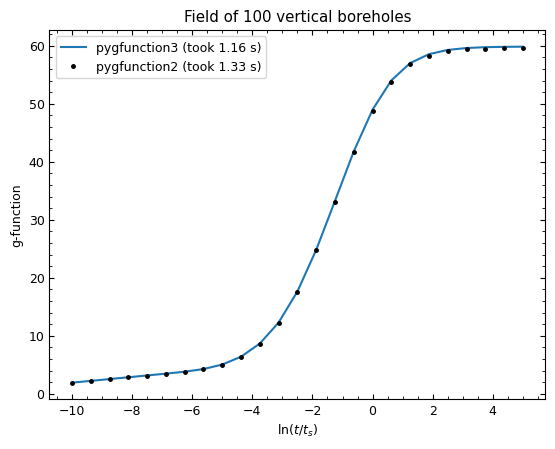

In [10]:
fig, ax = plt.subplots()
ax = gt3.plot._format_axis(ax, [r'$\ln(t / t_s)$', 'g-function'])
ax.set_title(f'Field of {field.n_boreholes} vertical boreholes')
ax.plot(np.log(time / t_s), g_func, label=f'pygfunction3 (took {time_elapsed:.2f} s)')
ax.plot(np.log(time / t_s), g_func_pygfunction, 'k.', label=f'pygfunction2 (took {time_elapsed_pygfunction:.2f} s)')
ax.legend()
plt.show()

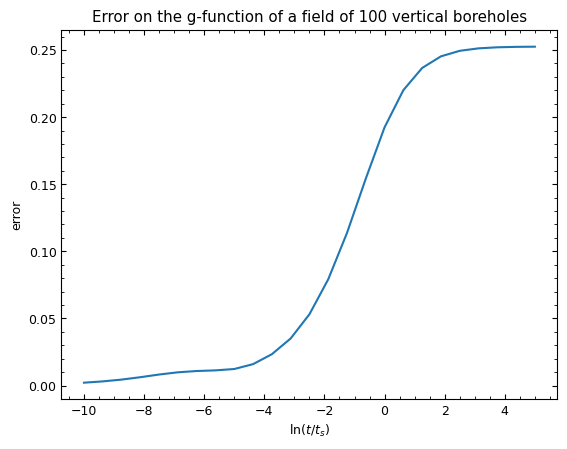

In [11]:
fig, ax = plt.subplots()
ax = gt3.plot._format_axis(ax, [r'$\ln(t / t_s)$', 'error'])
ax.set_title(f'Error on the g-function of a field of {field.n_boreholes} vertical boreholes')
ax.plot(np.log(time / t_s), (g_func - g_func_pygfunction))
plt.show()

### Field of 10 by 10 inclined boreholes

#### Borefield parameters

In [12]:
# Borehole dimensions and field layout
L = 150.        # Borehole length [m]
D = 4.          # Borehole buried depth [m]
r_b = 0.075     # Borehole radius [m]
tilt = np.radians(20.) # Borehole tilt angle [rad]
N_1 = 10         # Number of boreholes in x-direction
N_2 = 10         # Number of boreholes in y-direction
B = 7.5         # Borehole spacing [m]

# Positions of the boreholes
p_head = np.array(
    [np.tile(B * np.arange(N_1), N_2), np.repeat(B * np.arange(N_2), N_1)]
).T

# Orientation of the boreholes (all tilted away from (x = 0., y = 0.))
orientation = np.arctan2(p_head[:, 1], p_head[:, 0])

# Borefield object
field = gt3.Borefield(L=L, D=D, r_b=r_b, p_head=p_head, tilt=tilt, orientation=orientation)

#### Ground properties

In [13]:
k_s = 2.        # Soil conductivity [W/m/K]
alpha = 1e-6    # Soil diffusivity [m^2/s]

#### Parameters for the evaluation of g-functions

In [14]:
# Basis functions
n_nodes = 8
basis = gt3.Basis(n_nodes)

# Time array for g-function evaluation
t_s = L**2 / (9 * alpha)
tt_s = np.linspace(-10., 5., 25)
time = np.exp(tt_s) * t_s

#### Evaluation of the g-function

In [15]:
tic = perf_counter()
g_func, q_b, T_b = gt3.g_function(
    field,
    time=time,
    alpha=alpha,
    k_s=k_s,
    basis=basis,
    trf_backend='similarities',
    full_output=True,
    options={'rTol': 1e-2, 'sTol': 1e-2}
)
time_elapsed = perf_counter() - tic

Evaluating thermal response factors... done (4.62 seconds)
Solving for g-function... done (1.04 seconds)
Total time: 5.67 seconds


Time for the evaluation

In [16]:
%%timeit
g_func = gt3.g_function(
    field,
    time=time,
    alpha=alpha,
    k_s=k_s,
    basis=basis,
    trf_backend='similarities',
    options={'rTol': 1e-2, 'sTol': 1e-2},
    disp=False
)

5.12 s ± 146 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


Reference using pygfunction v2

In [17]:
field_pygfunction = gt.borefield.Borefield(
    L, D, r_b, p_head[..., 0], p_head[..., 1], tilt=tilt, orientation=orientation)
tic = perf_counter()
g_func_pygfunction = gt.gfunction.gFunction(
    field_pygfunction,
    alpha,
    time=time,
    method='similarities',
    options={'disp': True, 'nSegments': n_nodes}
).gFunc
time_elapsed_pygfunction = perf_counter() - tic

Identifying similarities ... 43.190 sec
------------------------------------------------------------
   Calculating g-function for boundary condition : 'UBWT'   
------------------------------------------------------------
Calculating segment to segment response factors ... 480.783 sec
Building and solving the system of equations ... 0.913 sec
Total time for g-function evaluation: 481.702 sec
------------------------------------------------------------


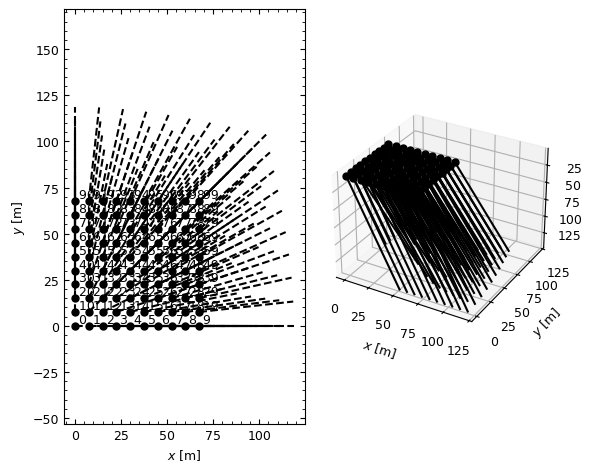

In [18]:
field_pygfunction.visualize_field();

Compare g-functions

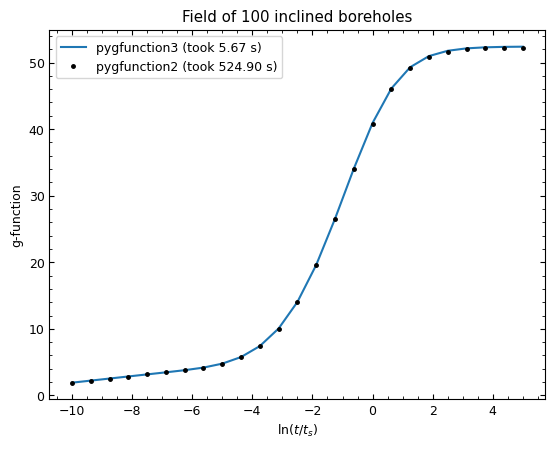

In [19]:
fig, ax = plt.subplots()
ax = gt3.plot._format_axis(ax, [r'$\ln(t / t_s)$', 'g-function'])
ax.set_title(f'Field of {field.n_boreholes} inclined boreholes')
ax.plot(np.log(time / t_s), g_func, label=f'pygfunction3 (took {time_elapsed:.2f} s)')
ax.plot(np.log(time / t_s), g_func_pygfunction, 'k.', label=f'pygfunction2 (took {time_elapsed_pygfunction:.2f} s)')
ax.legend()
plt.show()

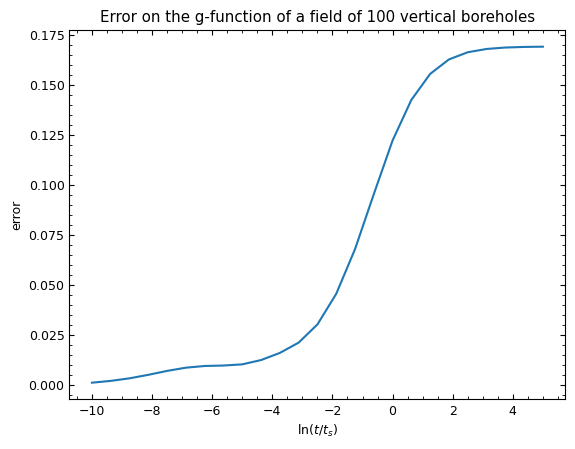

In [21]:
fig, ax = plt.subplots()
ax = gt3.plot._format_axis(ax, [r'$\ln(t / t_s)$', 'error'])
ax.set_title(f'Error on the g-function of a field of {field.n_boreholes} vertical boreholes')
ax.plot(np.log(time / t_s), (g_func - g_func_pygfunction))
plt.show()